# Identificação da planta e sintonia do PI

**PIDlampada** — Câmara Térmica Compacta com Controle PWM
UNIP · Engenharia de Computação · Projeto Integrador 2026

Este notebook fecha o ciclo entre o ensaio e o firmware:

1. lê o CSV que o firmware emite pela serial;
2. identifica um modelo de primeira ordem com atraso (FOPDT);
3. valida o modelo contra os dados medidos;
4. analisa a malha no domínio da frequência (Bode, margens, lugar das raízes);
5. compara quatro regras de sintonia em três cenários;
6. gera o trecho pronto para colar em `include/config.h`.

> O arquivo `exemplo_degrau.csv` é sintético, só para o notebook rodar de
> imediato. **Substitua pelo seu ensaio real** assim que o hardware estiver
> montado — os parâmetros de projeto são estimativas até lá.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import control as ct

import plant_id as pid

plt.rcParams.update({
    "figure.figsize": (10, 4.2),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
})

# ------------------------------------------------------------------ ajuste aqui
ENSAIO   = "exemplo_degrau.csv"   # <- troque pelo seu CSV
TS_S     = 60.0                   # periodo de amostragem do firmware
SETPOINT = 45.0                   # setpoint de projeto, em degC
# ------------------------------------------------------------------------------

df = pid.carregar_ensaio(ENSAIO)
print(f"{len(df)} amostras | {df.t_s.iloc[-1]/60:.0f} min de ensaio "
      f"| {df.T_c.min():.1f} a {df.T_c.max():.1f} degC")
df.head()

61 amostras | 60 min de ensaio | 24.5 a 54.0 degC


,t_s,T_c,setpoint_c,duty,erro_c,vbat_v,modo
0,0.0,24.60,45.0,1.0,20.40,12.06,DEGRAU
1,60.0,24.55,45.0,1.0,20.45,12.03,DEGRAU
2,120.0,24.52,45.0,1.0,20.48,12.03,DEGRAU
3,180.0,27.30,45.0,1.0,17.70,12.08,DEGRAU
4,240.0,29.65,45.0,1.0,15.35,12.04,DEGRAU


## 1. O ensaio em malha aberta

Degrau de duty aplicado com o comando `r` na serial. A lâmpada vai a 100 % e
a temperatura sobe até o regime permanente.

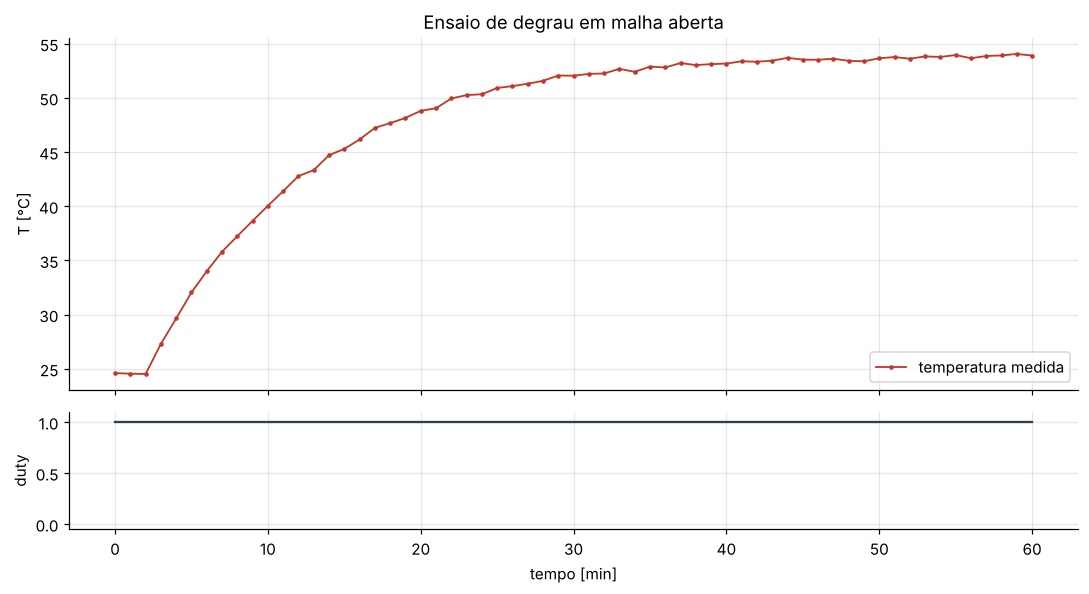

In [2]:
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(10, 5.5),
                               gridspec_kw={"height_ratios": [3, 1]})

ax1.plot(df.t_s/60, df.T_c, ".-", lw=1.2, ms=4, color="#c0392b", label="temperatura medida")
ax1.set_ylabel("T [°C]")
ax1.set_title("Ensaio de degrau em malha aberta")
ax1.legend(loc="lower right")

ax2.step(df.t_s/60, df.duty, where="post", color="#2c3e50")
ax2.set_ylabel("duty")
ax2.set_xlabel("tempo [min]")
ax2.set_ylim(-0.05, 1.1)
plt.tight_layout()

## 2. Identificação — dois métodos

**63,2 %** é o que todo mundo aprende primeiro: mede-se o instante em que a
resposta cruza 63,2 % do salto total e chama-se isso de τ. Funciona bem
quando não há atraso de transporte.

**Sundaresan & Krishnaswamy** usa dois pontos (35,3 % e 85,3 %) e separa o
atraso da constante de tempo:

    tau   = 0,67 * (t85 - t35)
    theta = 1,30 * t35 - 0,29 * t85

Aqui existe atraso real — o filamento leva alguns segundos para aquecer e o
sensor tem inércia própria. O método de um ponto não consegue distinguir
"demorou a começar" de "subiu devagar", então ele joga o atraso para dentro
de τ e superestima a constante de tempo.

In [3]:
modelos = {met: pid.identificar_fopdt(df, metodo=met) for met in ("63", "sundaresan")}

linhas = []
for met, m in modelos.items():
    _, mt = pid.validar_modelo(df, m)
    linhas.append({"método": met, "K [°C/duty]": round(m.K, 2),
                   "tau [s]": round(m.tau_s), "theta [s]": round(m.theta_s),
                   "RMSE [°C]": round(mt["rmse_c"], 3),
                   "erro máx [°C]": round(mt["erro_max_c"], 2),
                   "R²": round(mt["r2"], 5)})
pd.DataFrame(linhas).set_index("método")

,K [°C/duty],tau [s],theta [s],RMSE [°C],erro máx [°C],R²
método,,,,,,
63,29.27,755,0,1.128,4.38,0.98216
sundaresan,29.27,606,133,0.186,0.50,0.99952


G(s) = 29.27 * exp(-133s) / (606s + 1)   [degC / duty]


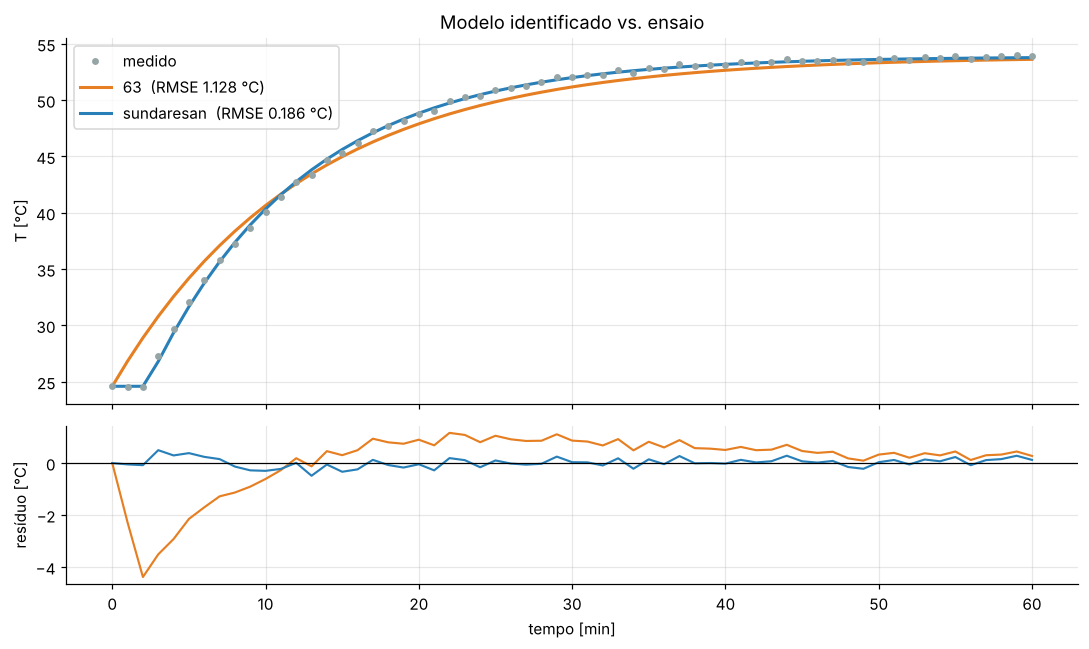

In [4]:
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(10, 6),
                               gridspec_kw={"height_ratios": [3, 1.3]})

ax1.plot(df.t_s/60, df.T_c, "o", ms=3.5, color="#95a5a6", label="medido", zorder=3)
cores = {"63": "#e67e22", "sundaresan": "#2980b9"}
for met, m in modelos.items():
    y_hat, mt = pid.validar_modelo(df, m)
    ax1.plot(df.t_s/60, y_hat, lw=2, color=cores[met],
             label=f"{met}  (RMSE {mt['rmse_c']:.3f} °C)")
ax1.set_ylabel("T [°C]")
ax1.set_title("Modelo identificado vs. ensaio")
ax1.legend()

for met, m in modelos.items():
    y_hat, _ = pid.validar_modelo(df, m)
    ax2.plot(df.t_s/60, df.T_c - y_hat, lw=1.4, color=cores[met])
ax2.axhline(0, color="k", lw=0.8)
ax2.set_ylabel("resíduo [°C]")
ax2.set_xlabel("tempo [min]")
plt.tight_layout()

m = modelos["sundaresan"]
print(m)

O resíduo do método de 63,2 % tem forma de **S** — erro sistemático, sinal de
que a estrutura do modelo está errada, não de que há ruído. O de Sundaresan
fica achatado em torno de zero, que é o que se espera quando sobra apenas
ruído de medição.

Daqui em diante usamos o modelo de Sundaresan.

## 3. Análise em frequência

Duas observações importantes antes dos números:

**O atraso efetivo não é só o do processo.** Amostrar a cada 60 s com
segurador de ordem zero equivale, em média, a meio período de atraso extra.
Ignorar esse `Ts/2` superestima a margem de fase — o sistema real é menos
robusto do que o papel sugere.

**O atraso é aproximado por Padé** para permitir o traçado do lugar das
raízes, que exige uma função racional.

In [5]:
theta_ef = m.theta_s + TS_S/2
print(f"theta do processo = {m.theta_s:.0f} s")
print(f"meio periodo de amostragem (ZOH) = {TS_S/2:.0f} s")
print(f"theta efetivo = {theta_ef:.0f} s      tau/theta_ef = {m.tau_s/theta_ef:.1f}")

G0 = ct.tf([m.K], [m.tau_s, 1])
num_p, den_p = ct.pade(theta_ef, 2)
G = ct.series(G0, ct.tf(num_p, den_p))
print("\nG(s) com atraso aproximado por Padé de 2a ordem:")
print(G)

theta do processo = 133 s
meio periodo de amostragem (ZOH) = 30 s
theta efetivo = 163 s      tau/theta_ef = 3.7

G(s) com atraso aproximado por Padé de 2a ordem:
<TransferFunction>: sys[2]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

        29.27 s^2 - 1.08 s + 0.01329
  ----------------------------------------
  606 s^3 + 23.36 s^2 + 0.312 s + 0.000454


A razão `tau/theta` acima de 3 indica uma planta **fácil de controlar** —
atraso pequeno frente à inércia. É por isso que um PI simples resolve e não
precisamos de termo derivativo (que, com sensor quantizado e amostragem de
60 s, só amplificaria ruído).

## 4. Regras de sintonia

Quatro regras clássicas, todas partindo do mesmo FOPDT. A conversão para o
formato do firmware importa: o `PIController` usa a **forma paralela**

    u = Kp*e + Ki*∫e dt

enquanto as regras são publicadas na **forma padrão**

    u = Kc*(e + (1/Ti)*∫e dt)

Logo `Kp = Kc` e `Ki = Kc/Ti`. Trocar isso é um erro silencioso: o sistema
funciona, só que com a ação integral centenas de vezes maior do que a
projetada.

In [6]:
regras = pid.sintonizar(m, Ts_s=TS_S)

tab = pd.DataFrame([{
    "regra": r.nome,
    "Kc": round(r.Kc, 4),
    "Ti [s]": round(r.Ti_s),
    "Kp (firmware)": round(r.Kp, 4),
    "Ki (firmware)": round(r.Ki, 7),
    "margem fase [°]": round(float(ct.margin(ct.series(ct.tf([r.Kc*r.Ti_s, r.Kc], [r.Ti_s, 0]), G))[1]), 1),
} for r in regras]).set_index("regra")
tab

,Kc,Ti [s],Kp (firmware),Ki (firmware),margem fase [°]
regra,,,,,
SIMC (Skogestad),0.0637,606,0.0637,0.000105,61.4
IMC,0.1111,687,0.1111,0.000162,42.5
Ziegler-Nichols (MA),0.1146,541,0.1146,0.000212,36.1
CHR 0 % sobressinal,0.0446,709,0.0446,0.000063,75.4


Margem de fase abaixo de 45° já é desconfortável; abaixo de 30°, o sistema
oscila na menor variação de parâmetro. Note onde Ziegler-Nichols cai.

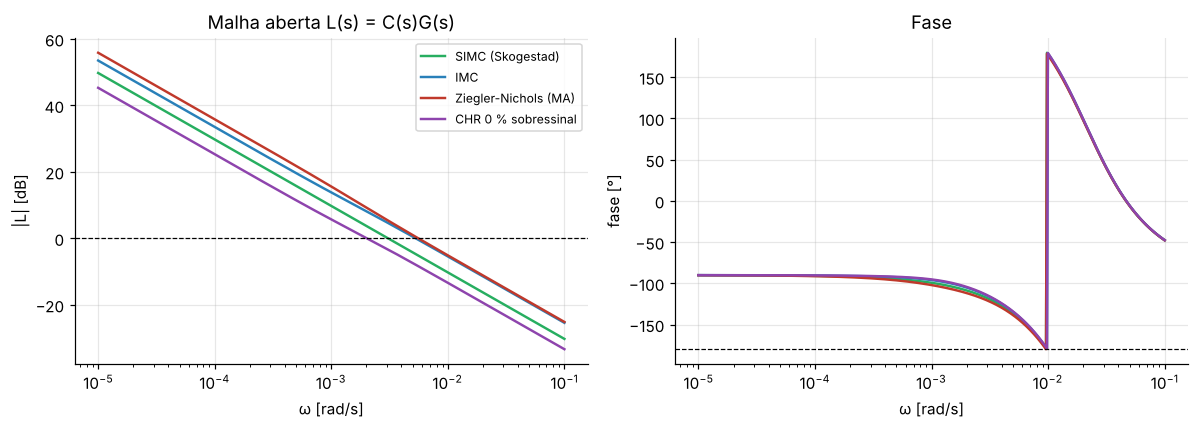

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for r, cor in zip(regras, ["#27ae60", "#2980b9", "#c0392b", "#8e44ad"]):
    C_pi = ct.tf([r.Kc*r.Ti_s, r.Kc], [r.Ti_s, 0])
    mag, fase, w = ct.frequency_response(ct.series(C_pi, G), np.logspace(-5, -1, 500))
    axes[0].semilogx(w, 20*np.log10(mag), lw=1.6, color=cor, label=r.nome)
    axes[1].semilogx(w, np.degrees(fase), lw=1.6, color=cor)

axes[0].axhline(0, color="k", lw=0.8, ls="--")
axes[0].set_ylabel("|L| [dB]"); axes[0].set_xlabel("ω [rad/s]")
axes[0].set_title("Malha aberta L(s) = C(s)G(s)"); axes[0].legend(fontsize=8)
axes[1].axhline(-180, color="k", lw=0.8, ls="--")
axes[1].set_ylabel("fase [°]"); axes[1].set_xlabel("ω [rad/s]")
axes[1].set_title("Fase")
plt.tight_layout()

## 5. Três cenários de validação

Simulação discreta reproduzindo **exatamente** o que o firmware faz:
amostragem de 60 s, saturação do duty em [0, 1] e anti-windup por clamping
condicional — o mesmo algoritmo de `lib/control/pi_controller.cpp`.

Um detalhe físico que muda a leitura de tudo: **o atuador só aquece**. Não há
Peltier nem ventilador, então o duty mínimo é zero e a descida depende apenas
da constante de tempo natural. Sobressinal aqui não é só feio — ele custa
caro, porque leva alguns τ para dissipar.

### 5.1 Partida a frio: 25 → 45 °C

O cenário da apresentação. Repare no duty.

,sobressinal [%],t_acom [min],erro regime [°C]
regra,,,
SIMC (Skogestad),0.0,40.0,-0.0
IMC,0.0,42.0,-0.0
Ziegler-Nichols (MA),0.0,34.0,-0.0
CHR 0 % sobressinal,0.0,49.0,-0.0


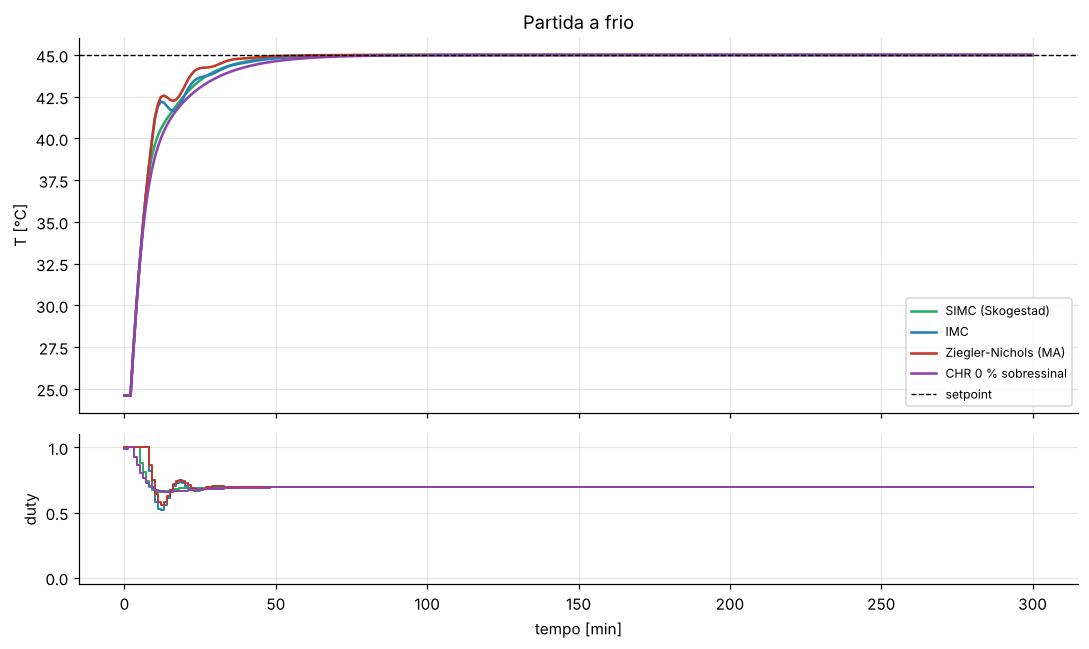

In [8]:
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(10, 6),
                               gridspec_kw={"height_ratios": [3, 1.2]})
res_frio = []
for r, cor in zip(regras, ["#27ae60", "#2980b9", "#c0392b", "#8e44ad"]):
    s = pid.simular_malha_fechada(m, r, SETPOINT, Ts_s=TS_S, t_final_s=5*3600)
    k = pid.metricas_resposta(s, SETPOINT)
    ax1.plot(s.t_s/60, s.T_c, lw=1.7, color=cor, label=r.nome)
    ax2.step(s.t_s/60, s.duty, where="post", lw=1.3, color=cor)
    res_frio.append({"regra": r.nome, "sobressinal [%]": round(k["sobressinal_pct"], 1),
                     "t_acom [min]": round(k["t_acomodacao_min"], 0),
                     "erro regime [°C]": round(k["erro_regime_c"], 3)})

ax1.axhline(SETPOINT, color="k", ls="--", lw=0.9, label="setpoint")
ax1.set_ylabel("T [°C]"); ax1.set_title("Partida a frio"); ax1.legend(fontsize=8)
ax2.set_ylabel("duty"); ax2.set_xlabel("tempo [min]"); ax2.set_ylim(-0.05, 1.1)
plt.tight_layout()
pd.DataFrame(res_frio).set_index("regra")

**Nenhuma das quatro sintonias ultrapassa o setpoint, e as curvas quase se
sobrepõem** — o tempo de acomodação varia pouco mais de 10 min entre a mais
rápida e a mais lenta. Isso não é erro de simulação: durante quase toda a
subida o duty está saturado em 1,0, ou seja, o sistema roda em **malha
aberta**. O controlador só volta a mandar
perto do setpoint, e o anti-windup impede que a integral exploda nesse meio
tempo.

Conclusão que vale para o relatório: **a partida a frio não serve para
comparar sintonias** nesta planta. Ela é limitada pelo atuador, não pelo
controlador.

### 5.2 Degrau pequeno de setpoint: 45 → 47 °C

Partindo do regime, com duty já equilibrado. Agora o controlador passa a
maior parte do transitório dentro da faixa linear — e as diferenças entre as
regras finalmente aparecem.

duty de equilibrio a 45 °C: 0.697


,sobressinal [%],pico [°C],t_acom [min],duty máx
regra,,,,
SIMC (Skogestad),1.5,47.03,9.0,0.862
IMC,32.8,47.66,27.0,0.977
Ziegler-Nichols (MA),36.6,47.73,28.0,1.000
CHR 0 % sobressinal,0.0,47.00,40.0,0.809


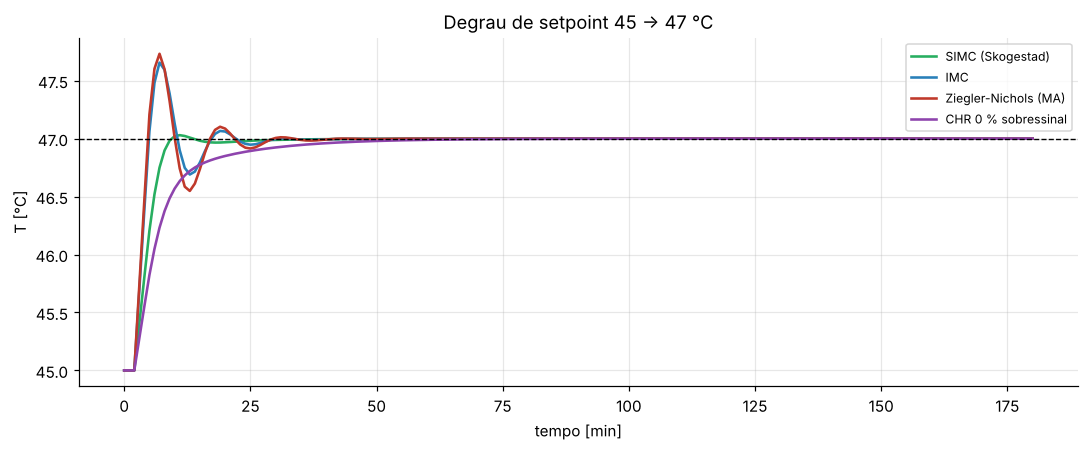

In [9]:
duty_eq = (SETPOINT - m.T0_c) / m.K
print(f"duty de equilibrio a {SETPOINT:.0f} °C: {duty_eq:.3f}")

fig, ax = plt.subplots(figsize=(10, 4.2))
res_peq = []
for r, cor in zip(regras, ["#27ae60", "#2980b9", "#c0392b", "#8e44ad"]):
    s = pid.simular_malha_fechada(m, r, SETPOINT+2, Ts_s=TS_S, t_final_s=3*3600,
                                  T_inicial_c=SETPOINT, duty_inicial=duty_eq)
    k = pid.metricas_resposta(s, SETPOINT+2)
    ax.plot(s.t_s/60, s.T_c, lw=1.7, color=cor, label=r.nome)
    res_peq.append({"regra": r.nome, "sobressinal [%]": round(k["sobressinal_pct"], 1),
                    "pico [°C]": round(k["pico_c"], 2),
                    "t_acom [min]": round(k["t_acomodacao_min"], 0),
                    "duty máx": round(s.duty.max(), 3)})

ax.axhline(SETPOINT+2, color="k", ls="--", lw=0.9)
ax.set_ylabel("T [°C]"); ax.set_xlabel("tempo [min]")
ax.set_title("Degrau de setpoint 45 → 47 °C"); ax.legend(fontsize=8)
plt.tight_layout()
pd.DataFrame(res_peq).set_index("regra")

### 5.3 Rejeição de perturbação: ambiente cai 6 °C

O caso mais realista — alguém abre a janela, o ar-condicionado liga. Setpoint
fixo, o controlador tem que compensar sozinho. É aqui que se vê a diferença
entre ser rápido e ser estável.

,desvio máx [°C],IAE [°C·s],recuperação [min],duty pico
regra,,,,
SIMC (Skogestad),2.12,1951,32,0.905
IMC,1.84,1268,27,0.969
Ziegler-Nichols (MA),1.83,968,20,0.992
CHR 0 % sobressinal,2.38,3261,47,0.902


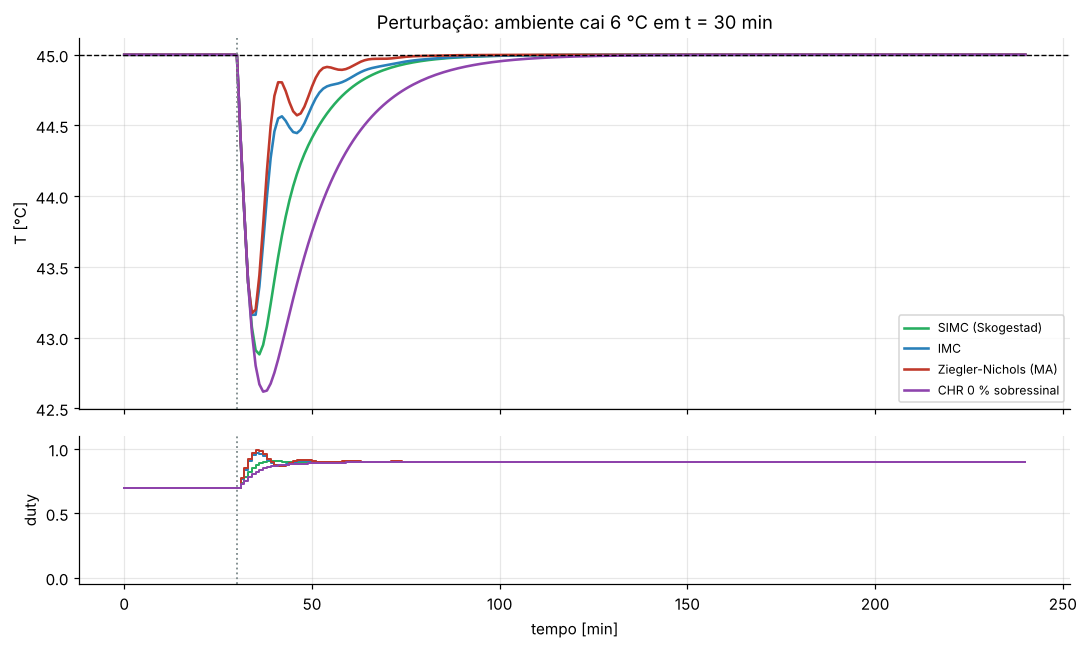

In [10]:
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(10, 6),
                               gridspec_kw={"height_ratios": [3, 1.2]})
T_PERT, DELTA_AMB = 1800.0, -6.0
res_pert = []
for r, cor in zip(regras, ["#27ae60", "#2980b9", "#c0392b", "#8e44ad"]):
    s = pid.simular_malha_fechada(m, r, SETPOINT, Ts_s=TS_S, t_final_s=4*3600,
                                  T_inicial_c=SETPOINT, duty_inicial=duty_eq,
                                  perturbacao_c=DELTA_AMB, t_perturbacao_s=T_PERT)
    pos = s[s.t_s >= T_PERT]
    desvio = float((pos.T_c - SETPOINT).abs().max())
    iae = float(np.trapezoid((pos.T_c - SETPOINT).abs(), pos.t_s))
    fora = pos[(pos.T_c - SETPOINT).abs() > 0.2]
    rec = (float(fora.t_s.iloc[-1]) - T_PERT)/60 if len(fora) else 0.0
    ax1.plot(s.t_s/60, s.T_c, lw=1.7, color=cor, label=r.nome)
    ax2.step(s.t_s/60, s.duty, where="post", lw=1.3, color=cor)
    res_pert.append({"regra": r.nome, "desvio máx [°C]": round(desvio, 2),
                     "IAE [°C·s]": round(iae), "recuperação [min]": round(rec),
                     "duty pico": round(float(pos.duty.max()), 3)})

ax1.axhline(SETPOINT, color="k", ls="--", lw=0.9)
ax1.axvline(T_PERT/60, color="#7f8c8d", ls=":", lw=1.2)
ax1.set_ylabel("T [°C]"); ax1.legend(fontsize=8)
ax1.set_title(f"Perturbação: ambiente cai {abs(DELTA_AMB):.0f} °C em t = {T_PERT/60:.0f} min")
ax2.axvline(T_PERT/60, color="#7f8c8d", ls=":", lw=1.2)
ax2.set_ylabel("duty"); ax2.set_xlabel("tempo [min]"); ax2.set_ylim(-0.05, 1.1)
plt.tight_layout()
pd.DataFrame(res_pert).set_index("regra")

## 6. Escolha e exportação

O compromisso fica explícito nas duas tabelas anteriores: Ziegler-Nichols
rejeita perturbação mais rápido (menor IAE), mas paga com sobressinal alto no
seguimento de setpoint e um duty de pico quase encostado na saturação — sem
margem para um dia mais frio.

**SIMC** fica no meio: sobressinal baixo, IAE razoável e folga de atuador. Para
uma planta que só aquece e cujo teto é um limite de material (o PMMA amolece
perto de 80 °C), errar para o lado conservador é a decisão certa.

In [11]:
ESCOLHIDA = regras[0]          # 0 = SIMC, 1 = IMC, 2 = ZN, 3 = CHR
print(pid.gerar_config_h(m, ESCOLHIDA))

// ---- valores obtidos do ensaio de degrau + sintonia SIMC (Skogestad) ----
// Modelo identificado: G(s) = 29.27 * exp(-133s) / (606s + 1)   [degC / duty]
constexpr float PI_KP = 0.063662f;   // 1/degC
constexpr float PI_KI = 0.00010506f;   // 1/(degC*s)   (Ti = 606 s)

constexpr float PLANT_TAU_S     = 606.0f;
constexpr float PLANT_GAIN_C    = 29.27f;
constexpr float PLANT_AMBIENT_C = 24.6f;


Cole o trecho acima em `include/config.h`, recompile e repita o ensaio —
agora em malha fechada — para confirmar na bancada o que a simulação previu:

```powershell
pio run -e esp32dev -t upload
pio device monitor -e esp32dev | Tee-Object -FilePath docs\ensaios\malhafechada_01.csv
```

Na serial, `s 45` para o setpoint. Se a resposta real divergir muito desta
previsão, o modelo é que está errado — refaça o ensaio de degrau com o
hardware já na configuração final (tampa fechada, sensor na posição
definitiva) e rode este notebook de novo.

---

### Resumo

| Etapa | Resultado |
|---|---|
| Identificação | FOPDT por Sundaresan separa τ de θ; o método dos 63,2 % infla τ |
| Atraso efetivo | θ do processo + Ts/2 do ZOH — esquecer o ZOH infla a margem de fase |
| Partida a frio | não diferencia sintonias: o atuador satura e o sistema roda em malha aberta |
| Degrau pequeno | revela o sobressinal real de cada regra |
| Perturbação | melhor cenário de comparação; expõe o custo da agressividade |
| Decisão | SIMC — atuador unidirecional e teto de material pedem conservadorismo |